In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway
from scipy.stats import pearsonr
from scipy.stats import chi2_contingency
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_regression, f_regression



In [2]:
df = pd.read_csv('automobileEDA.csv')
print('\nFirst 5 rows')
df.head(5)



First 5 rows


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [3]:
df.shape

(201, 29)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    object 
 3   aspiration         201 non-null    object 
 4   num-of-doors       201 non-null    object 
 5   body-style         201 non-null    object 
 6   drive-wheels       201 non-null    object 
 7   engine-location    201 non-null    object 
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    object 
 14  num-of-cylinders   201 non-null    object 
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non

In [5]:
num_cols = df.select_dtypes(include='number').columns
#df[num_cols].corr()['price'].sort_values(ascending = False)
corr_with_price = df[num_cols].corr()['price'].sort_values(ascending = False)
corr_with_price.round(2)

price                1.00
engine-size          0.87
curb-weight          0.83
horsepower           0.81
city-L/100km         0.79
width                0.75
length               0.69
wheel-base           0.58
bore                 0.54
height               0.14
normalized-losses    0.13
diesel               0.11
stroke               0.08
compression-ratio    0.07
symboling           -0.08
peak-rpm            -0.10
gas                 -0.11
city-mpg            -0.69
highway-mpg         -0.70
Name: price, dtype: float64

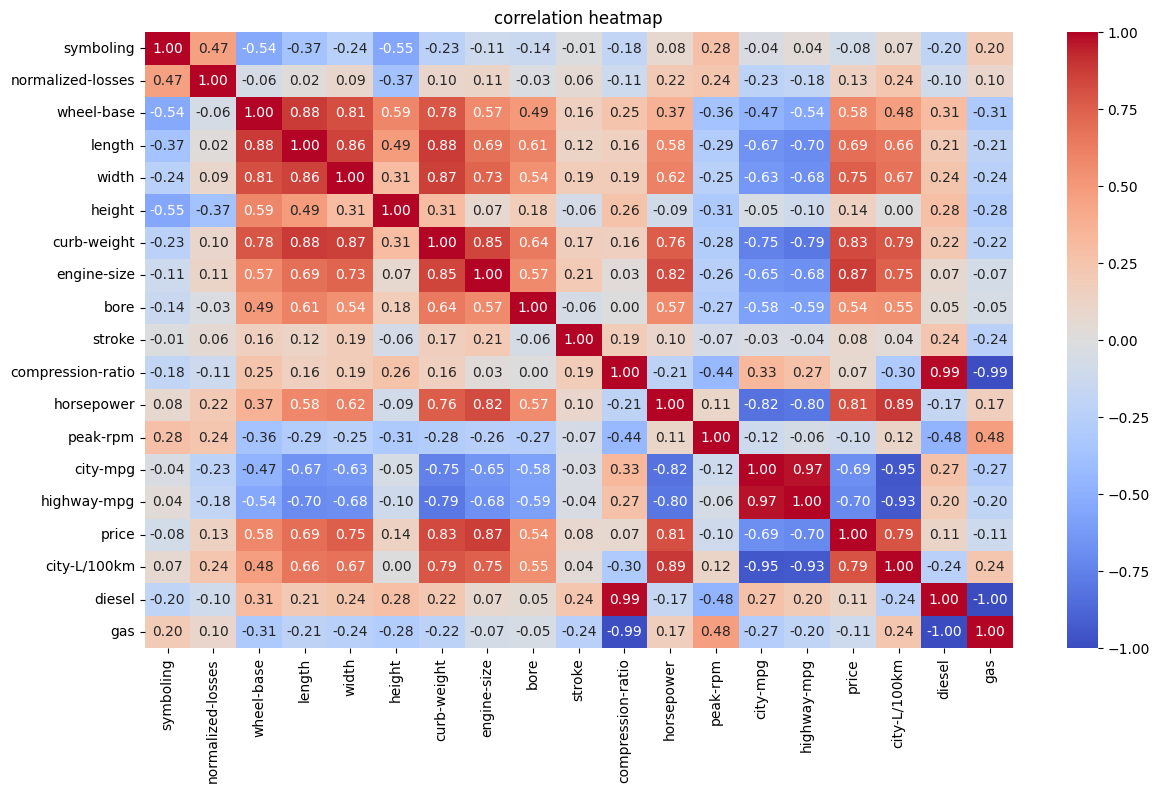

In [6]:
plt.figure(figsize=(14,8))
sns.heatmap(df[num_cols].corr(), annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.title('correlation heatmap')
plt.show()

In [7]:
strong_numeric = corr_with_price[abs(corr_with_price)>0.5].index.tolist()
strong_numeric.remove('price')
strong_numeric

['engine-size',
 'curb-weight',
 'horsepower',
 'city-L/100km',
 'width',
 'length',
 'wheel-base',
 'bore',
 'city-mpg',
 'highway-mpg']

In [8]:
cat_cols = df.select_dtypes(exclude='number').columns
#corr_with_price = df[cat_cols].corr()['price'].sort_values(ascending= False)
cat_cols

Index(['make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels',
       'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system',
       'horsepower-binned'],
      dtype='object')

In [9]:
selected_categorical = []
for col in cat_cols:
    price_group = [group['price'].values for _, group in df.groupby(col)]
    f_stat, p_value = f_oneway(*price_group)
    if p_value < 0.05:
        print(f"  {col:20s} p = {p_value:.2e}  -> related to price")
        selected_categorical.append(col)
    else:
        print(f"  {col:20s} p = {p_value:.2e}  -> NOT related to price")

  make                 p = 1.07e-50  -> related to price
  aspiration           p = 1.07e-02  -> related to price
  num-of-doors         p = 5.50e-01  -> NOT related to price
  body-style           p = 8.78e-07  -> related to price
  drive-wheels         p = 3.39e-23  -> related to price
  engine-location      p = 1.58e-06  -> related to price
  engine-type          p = 2.09e-08  -> related to price
  num-of-cylinders     p = 2.87e-39  -> related to price
  fuel-system          p = 1.31e-15  -> related to price
  horsepower-binned    p = 2.81e-31  -> related to price


In [10]:
cat_cols[cat_cols==' related to price']

Index([], dtype='object')

In [11]:
selected_cols = strong_numeric + selected_categorical + ['price']
for col in ['city-L/100km', 'horsepower-binned', 'engine-location']:
    if col in selected_cols:
        selected_cols.remove(col)

df = df[selected_cols]
df.shape

(201, 17)

MIissing Values

In [12]:
missing = df.isnull().sum()
print(missing[missing>0])

Series([], dtype: int64)


In [13]:
df[df.isnull().any(axis=1)]

,engine-size,curb-weight,horsepower,width,length,wheel-base,bore,city-mpg,highway-mpg,make,aspiration,body-style,drive-wheels,engine-type,num-of-cylinders,fuel-system,price


In [14]:
dups = df.duplicated().sum()
dups

np.int64(0)

OUTLIERS

  wheel-base           3
  length               1
  width                11
  curb-weight          2
  engine-size          10
  bore                 0
  horsepower           5
  city-mpg             2
  highway-mpg          3


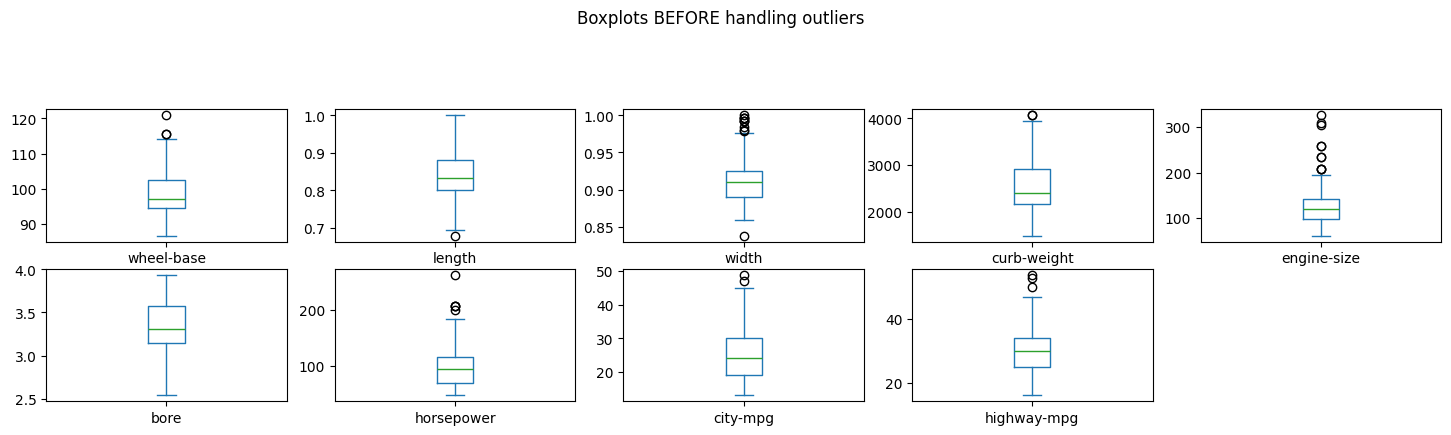

In [15]:

check_cols = []
for c in num_cols:
    if c in df.columns and c != 'price':
        check_cols.append(c)
def iqr_limits(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3-q1
    return q1 - (1.5*iqr), q3+(1.5*iqr)
for col in check_cols:
    low,high = iqr_limits(df[col])
    n_out = ((df[col]<low)|(df[col]>high)).sum()
    print(f"  {col:20s} {n_out}")

df[check_cols].plot(kind='box', subplots=True, layout=(5, 5),figsize=(18, 10))
plt.suptitle("Boxplots BEFORE handling outliers")
plt.show()
    
    

In [16]:
#for col in num_cols:
 #   low, high = iqr_limits(df[col])
  ## print(f"  {col:20s} {n_out}")

In [17]:
check_cols = []
for c in num_cols:
    if c in df.columns and c != 'price':
        check_cols.append(c)
keep_row = pd.Series(True, index=df.index)

for col in check_cols:
    low, high = iqr_limits(df[col])
    inside = (df[col]>=low)&(df[col]<=high)
    keep_row = keep_row & inside
print('Rows to remove:', (~keep_row).sum())

#removing rows
df = df[keep_row]
print('New shape:', df.shape)


    
        

Rows to remove: 21
New shape: (180, 17)


In [18]:
#df = df.drop(columns=['num-of-doors',       # not related to price (p = 0.55)
 #                     'horsepower-binned',   # duplicate of horsepower
  #                     'gas'])                # duplicate of diesel

In [19]:
print("\nFinal shape:", df.shape)
print("Missing values left:", df.isnull().sum().sum())
print("Duplicate rows left:", df.duplicated().sum())


Final shape: (180, 17)
Missing values left: 0
Duplicate rows left: 0


In [20]:
df.to_csv('Yine_Data.csv', index=False)

Question 1: Exploring and cleaning the data

What I did:
I loaded automobileEDA.csv and looked at the first 5 rows.
Each row is one car. The columns describe the make,body style, engine and size of the car. 
The column price is the target variable I want to explain.


The data has 201 cars (rows) and 29 columns.
Most columns have no missing values. Only stroke has 4 missing values and horsepower-binned has 1. 
Number columns are int or float, and text columns are object.   


I did feature selection as part of cleaning, so that the cleaned file only keeps variables that are linked to price.
For the number columns I used correlation with price (the Pearson r).

Strong positive links: engine-size 0.87, curb-weight 0.83, horsepower 0.81, city-L/100km 0.79, width 0.75, length 0.69, wheel-base 0.58 and bore 0.54.

Strong negative links: highway-mpg -0.70 and city-mpg -0.69. Cars that use less fuel tend to cost less.

Weak links (close to 0): height, normalized-losses, diesel, gas, stroke, compression-ratio, symboling and peak-rpm.
These have little to say about price.  

The heatmap shows the correlation between every pair of number columns.
The last row shows each variable against price, the same values as above. 
It also shows that size and power variables such as engine-size, curb-weight and horsepower move together, and that city-mpg and highway-mpg move together.


I kept the number columns with a correlation above 0.5 (either direction).
This gives 10 columns: engine-size, curb-weight, horsepower, city-L/100km, width, length, wheel-base, bore, city-mpg and highway-mpg.


For text (categorical) columns I used a one-way ANOVA test against price.

Null hypothesis: the average price is the same in every group of the column.
If the p-value is below 0.05, I reject it and keep the column, because the average price differs between groups.

All columns were related to price except num-of-doors (p = 0.55), so I dropped it. 
The columns kept are make, aspiration, body-style, drive-wheels, engine-location, engine-type, num-of-cylinders, fuel-system and horsepower-binned.

I then removed three more columns:

city-L/100km gives the same information as city-mpg in different units.

horsepower-binned gives the same information as horsepower, only put in groups.

engine-location has almost every car in one group (front), so it carries very little information.

The result has 17 columns: 9 number columns, 7 text columns and price.


There are no missing values in the selected columns.
The two columns that had gaps, stroke and horsepower-binned, were not selected, so there was nothing to fill.
There are also 0 duplicate rows, so no rows were removed here.

I used the IQR rule to find outliers. A value is an outlier if it is below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR.
The dots beyond the whiskers in the boxplots are these outliers.

The most outliers are in width (11) and engine-size (10), then horsepower (5), wheel-base (3), highway-mpg (3), curb-weight (2), city-mpg (2) and length (1). bore has none. 
I did not check price, because it is the target and expensive cars are real cars, not mistakes.

I removed every row that is an outlier in any number column. 
This removed 21 rows, so the data went from 201 to 180 rows (about 10%).
I accepted this loss to get cleaner results for the later analysis.

The cleaned data has 180 rows and 17 columns, with 0 missing values and 0 duplicate rows. 
I saved it as Yine.Data.csv.

Question 2

In [21]:
df = pd.read_csv('Yine_Data.csv')

In [22]:

num_cols = df.select_dtypes(include = 'number').columns
cat_cols = df.select_dtypes(exclude = 'number').columns

df.shape

(180, 17)

In [23]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
engine-size,180.0,118.600000,26.488450,70.000000,97.000000,110.000000,136.000000,183.000000
curb-weight,180.0,2484.050000,433.297816,1819.000000,2143.750000,2395.000000,2812.750000,3750.000000
horsepower,180.0,97.119513,28.829855,52.000000,70.000000,93.000000,114.000000,175.000000
width,180.0,0.910918,0.022975,0.858333,0.888889,0.908333,0.923611,0.976389
length,180.0,0.831449,0.051800,0.694858,0.799135,0.830370,0.855118,0.955790
wheel-base,180.0,98.365556,5.163725,86.600000,94.500000,96.700000,100.400000,114.200000
bore,180.0,3.315217,0.261676,2.540000,3.150000,3.310000,3.550000,3.940000
city-mpg,180.0,25.694444,5.441509,16.000000,21.000000,25.000000,30.000000,38.000000
highway-mpg,180.0,31.283333,5.772479,22.000000,27.000000,31.000000,36.000000,47.000000
price,180.0,11400.894444,4850.349998,5118.000000,7725.750000,9959.500000,14584.000000,28248.000000


In [24]:
df[num_cols].skew().round(2)

engine-size    0.73
curb-weight    0.55
horsepower     0.77
width          0.61
length         0.06
wheel-base     1.09
bore           0.02
city-mpg       0.35
highway-mpg    0.42
price          1.08
dtype: float64

In [25]:
for col in cat_cols:
    print(f'\n--- {col} ---')
    counts = df[col].value_counts()
    percent = (df[col].value_counts(normalize=True)*100).round(1)
    print(pd.DataFrame({'count':counts,'percent': percent}))


--- make ---
               count  percent
make                         
toyota            32     17.8
mazda             17      9.4
nissan            16      8.9
mitsubishi        13      7.2
volkswagen        12      6.7
subaru            12      6.7
honda             12      6.7
peugot            11      6.1
volvo             11      6.1
dodge              9      5.0
plymouth           7      3.9
saab               6      3.3
bmw                5      2.8
audi               3      1.7
mercedes-benz      3      1.7
alfa-romero        3      1.7
isuzu              2      1.1
renault            2      1.1
chevrolet          2      1.1
mercury            1      0.6
porsche            1      0.6

--- aspiration ---
            count  percent
aspiration                
std           147     81.7
turbo          33     18.3

--- body-style ---
             count  percent
body-style                 
sedan           82     45.6
hatchback       65     36.1
wagon           24     13.3
hardtop 

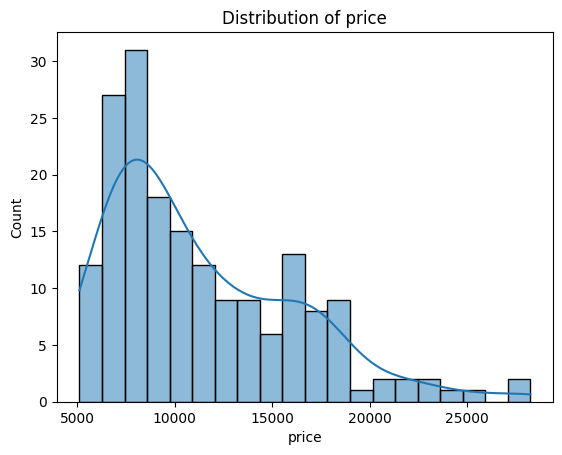

In [26]:
#Price
sns.histplot(df['price'], kde=True, bins = 20)
plt.title('Distribution of price')
plt.show()

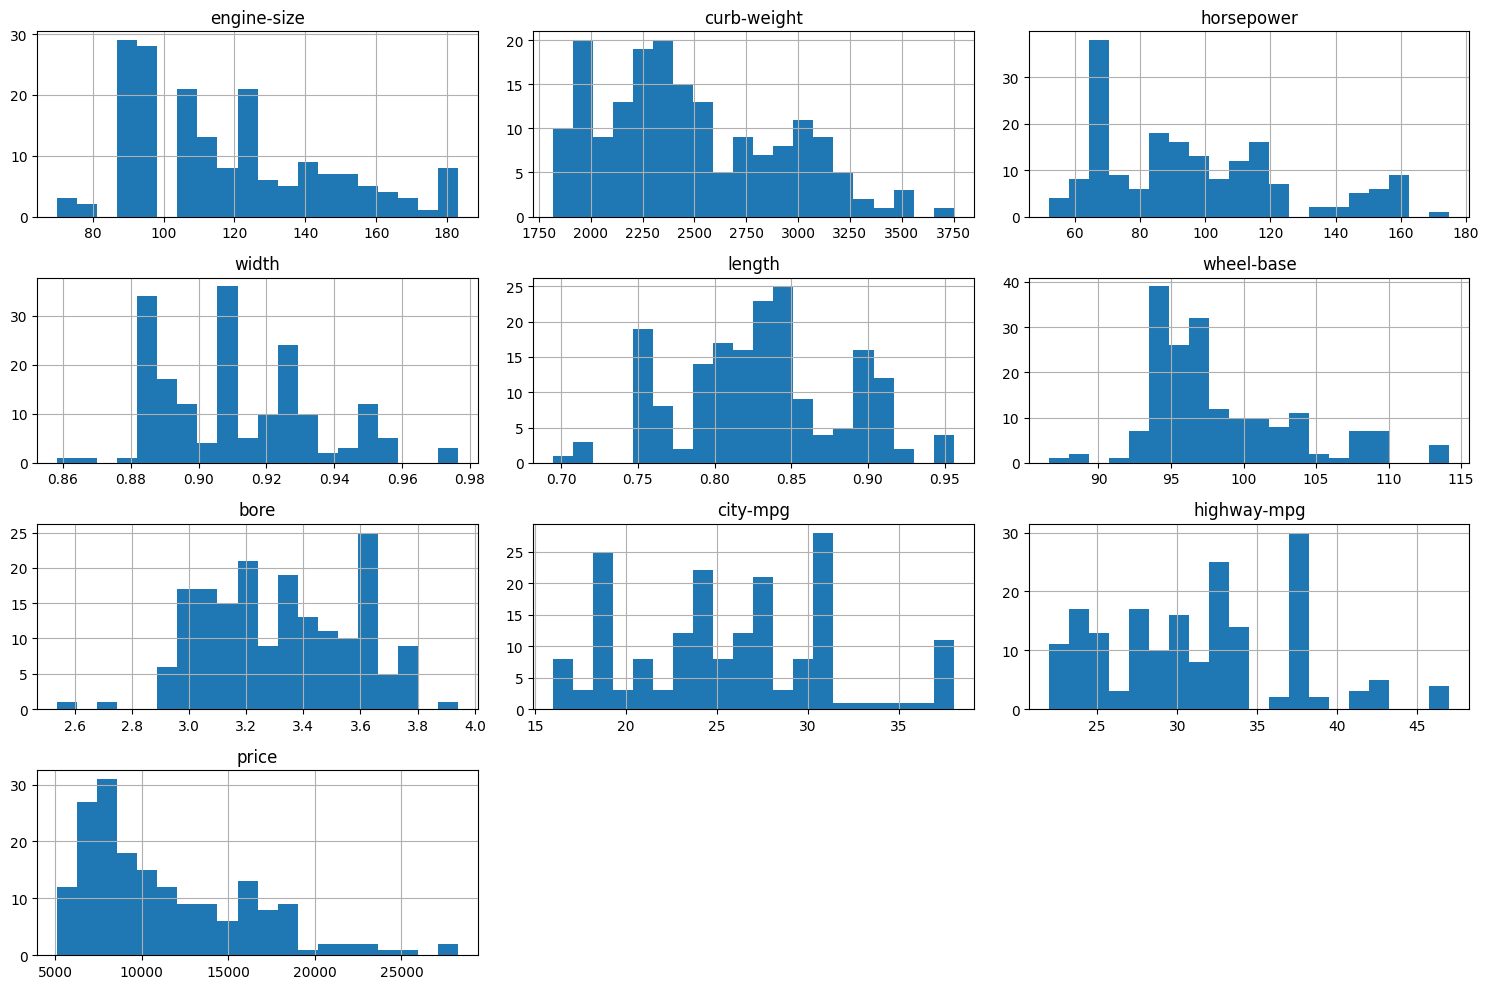

In [27]:
df[num_cols].hist(bins = 20, figsize=(15,10))
plt.tight_layout()
plt.show()

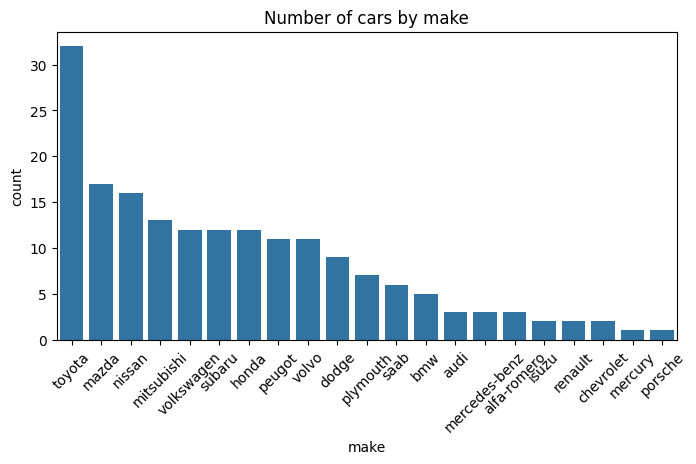

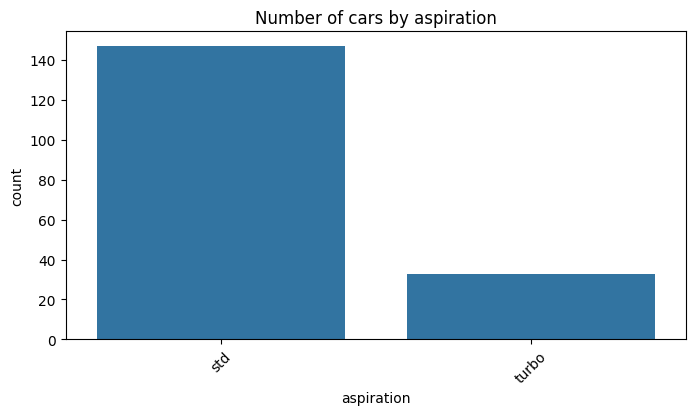

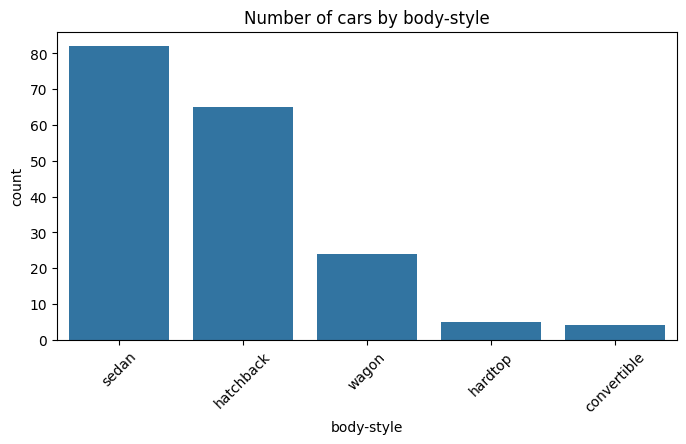

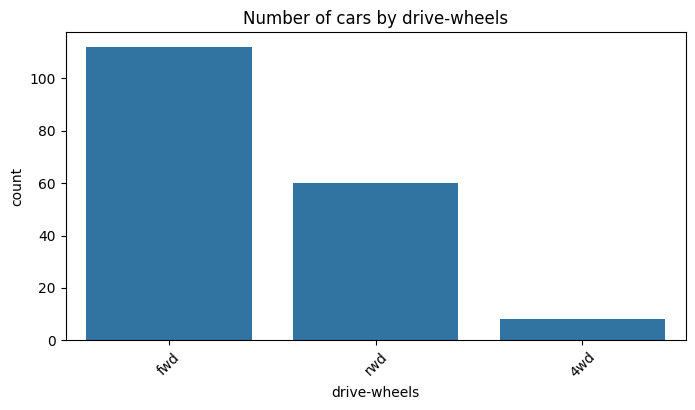

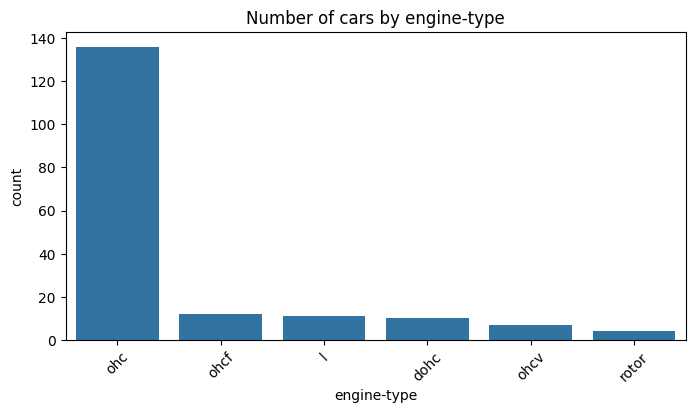

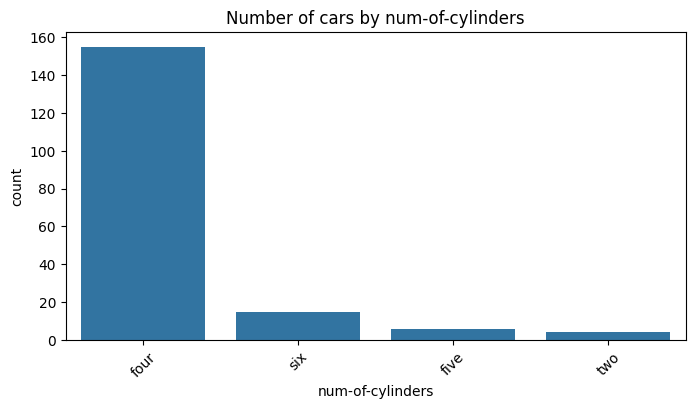

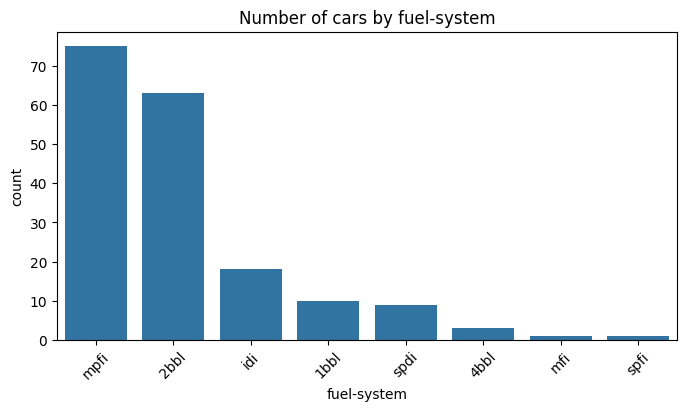

In [28]:
for col in cat_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(x=col, data=df, order=df[col].value_counts().index)
    plt.xticks(rotation=45)
    plt.title(f'Number of cars by {col}')
    plt.show()

Price: the average is about 11,401 and the median is about 9,960. The mean is higher than the median because a few expensive cars pull it up. Prices go from 5,118 to 28,248, with a standard deviation of about 4,850.

Other variables: engine-size averages about 119 (range 70 to 183), curb-weight about 2,484 (1,819 to 3,750), horsepower about 97 (52 to 175), city-mpg about 25.7 and highway-mpg about 31.3. width and length are small decimal numbers (about 0.86 to 0.98 and 0.69 to 0.96), which means they are already scaled and are not real measurements.

Skewness shows which way a column leans. Above 1 means a clear tail to the right. Price (1.08) and wheel-base (1.09) have a clear right tail: most cars are lower priced with a few very expensive ones. engine-size, horsepower, width and curb-weight lean slightly right (0.55 to 0.77). length (0.06) and bore (0.02) are almost balanced, and city-mpg and highway-mpg are only slightly skewed.

Make: Toyota is the most common (32 cars, 17.8%), then Mazda and Nissan. Many makes have only 1 to 3 cars.
Aspiration: 147 cars are standard (81.7%) and 33 are turbo (18.3%).
Body style: sedan 82 (45.6%) and hatchback 65 (36.1%) make up most cars. Wagon has 24, hardtop 5 and convertible 4.
Drive wheels: fwd 112 (62.2%), rwd 60 (33.3%) and 4wd 8 (4.4%).
Engine type: ohc is by far the most common (136, 75.6%).
Number of cylinders: four cylinders is 155 cars (86.1%).
Fuel system: mpfi 75 (41.7%) and 2bbl 63 (35.0%) are the most common.

Many groups are very small, so results about them are less reliable.

Most cars cost between about 6,000 and 10,000, and the most common band is about 7,000 to 9,000. After that the bars get lower and a long tail stretches to the right up to about 28,000. This confirms that price is right-skewed: there are many cheaper cars and only a few expensive ones.

engine-size, horsepower, curb-weight and wheel-base are bunched at the smaller values with a tail to the right. This means most cars are small and light, and a few are large and powerful. length, width and bore are more balanced with some gaps. city-mpg and highway-mpg are spread out with a few tall bars, because many cars share the same fuel use values.

The count plots show the same pattern as the frequency table. A few groups dominate: standard aspiration, sedan and hatchback bodies, front-wheel drive, ohc engines and four cylinders. The rest of the groups are small.


Question 3

In [29]:
df = pd.read_csv('Yine_Data.csv')


In [30]:
for col in ['drive-wheels','body-style']:
    print(f'\n--- Average price by {col}---')
    '''piles by col,thenfor eachpile: mean,median, number of cars '''
    summary = df.groupby(col)['price'].agg(['mean','median','count']).round(0)
    print(summary.sort_values('mean'))


--- Average price by drive-wheels---
                 mean   median  count
drive-wheels                         
fwd            9033.0   8192.0    112
4wd           10241.0   9006.0      8
rwd           15976.0  16500.0     60

--- Average price by body-style---
                mean   median  count
body-style                          
hatchback     9935.0   8845.0     65
sedan        12086.0  10270.0     82
wagon        12099.0  10946.0     24
hardtop      13142.0   9639.0      5
convertible  14815.0  14998.0      4


body-style    convertible  hardtop  hatchback    sedan    wagon
drive-wheels                                                   
4wd                   NaN      NaN     7603.0  12647.0   9096.0
fwd               11595.0   8249.0     8506.0   9442.0   9186.0
rwd               15888.0  14366.0    14022.0  17116.0  16994.0


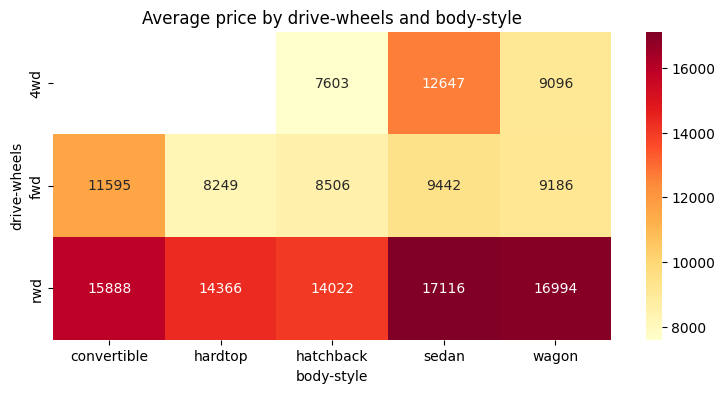

                             mean  count
drive-wheels body-style                 
4wd          hatchback     7603.0      1
fwd          hardtop       8249.0      1
             hatchback     8506.0     47
4wd          wagon         9096.0      4
fwd          wagon         9186.0     11
             sedan         9442.0     52
             convertible  11595.0      1
4wd          sedan        12647.0      3
rwd          hatchback    14022.0     17
             hardtop      14366.0      4
             convertible  15888.0      3
             wagon        16994.0      9
             sedan        17116.0     27


In [31]:
pivot = df.pivot_table(values='price', index='drive-wheels',columns='body-style', aggfunc='mean').round(0)
print(pivot)

plt.figure(figsize=(9, 4))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd')   # darker = more expensive
plt.title('Average price by drive-wheels and body-style')
plt.show()

combo = df.groupby(['drive-wheels', 'body-style'])['price'].agg(['mean', 'count']).round(0)
print(combo.sort_values('mean'))

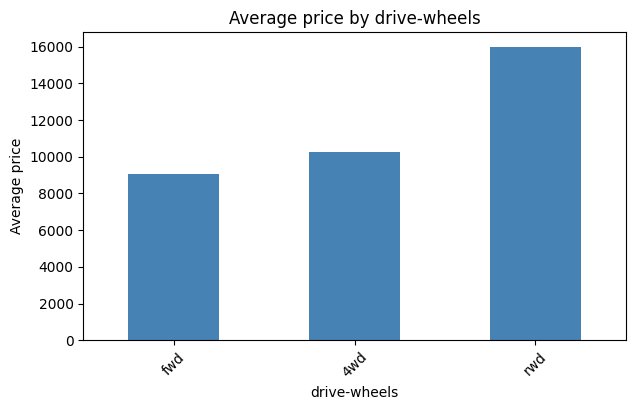

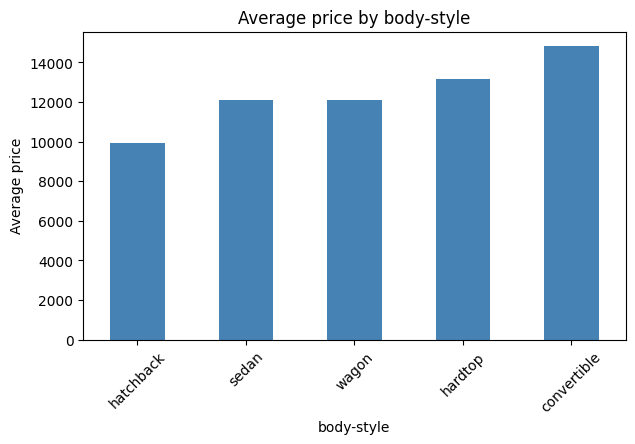

In [32]:
for col in ['drive-wheels', 'body-style']:
    avg_price = df.groupby(col)['price'].mean().sort_values()
    avg_price.plot(kind='bar', color='steelblue', figsize=(7, 4))
    plt.ylabel('Average price')
    plt.title(f'Average price by {col}')
    plt.xticks(rotation=45)
    plt.show()

In [33]:
for col in ['drive-wheels', 'body-style']:
    avg_price = df.groupby(col)['price'].mean()
    print(f"{col}: highest = {avg_price.idxmax()} ({avg_price.max():.0f}), "
          f"lowest = {avg_price.idxmin()} ({avg_price.min():.0f})")

drive-wheels: highest = rwd (15976), lowest = fwd (9033)
body-style: highest = convertible (14815), lowest = hatchback (9935)


In [34]:
cat_cols = df.select_dtypes(exclude='number').columns
for col in cat_cols:
    avg_price = df.groupby(col)['price'].mean()
    print(f"{col:18s} highest: {avg_price.idxmax()} ({avg_price.max():.0f}) | "
          f"lowest: {avg_price.idxmin()} ({avg_price.min():.0f})")

make               highest: mercedes-benz (27325) | lowest: chevrolet (6435)
aspiration         highest: turbo (15455) | lowest: std (10491)
body-style         highest: convertible (14815) | lowest: hatchback (9935)
drive-wheels       highest: rwd (15976) | lowest: fwd (9033)
engine-type        highest: ohcv (16426) | lowest: ohcf (8541)
num-of-cylinders   highest: five (21328) | lowest: four (10349)
fuel-system        highest: idi (15448) | lowest: 2bbl (7469)


I grouped the cars by drive-wheels and body-style and found the mean, median and count of price for each group.

Drive wheels: rwd has the highest average price (about 15,976), then 4wd (about 10,241) and fwd (about 9,033).
Body style: convertible is highest (about 14,815), then hardtop (about 13,142), wagon (about 12,099), sedan (about 12,086) and hatchback is lowest (about 9,935).

The convertible (4 cars), hardtop (5 cars) and 4wd (8 cars) groups are small, so their averages are less reliable.


This table and heatmap show the average price for each combination of drive-wheels and body-style. Darker colours mean higher prices.

Rear-wheel drive cars are the most expensive in every body style, for example rwd sedan (about 17,116) and rwd wagon (about 16,994). Front-wheel drive cars are the cheapest, for example fwd hatchback (about 8,506) and fwd sedan (about 9,442).

Among groups with a good number of cars, rwd sedan (27 cars) is the highest and fwd hatchback (47 cars) is the lowest. A few combinations have only 1 car (for example 4wd hatchback and fwd hardtop), so I do not trust those numbers.


The bar charts show the same results. For drive wheels the highest is rwd (15,976) and the lowest is fwd (9,033). For body style the highest is convertible (14,815) and the lowest is hatchback (9,935).

Across all text columns: make: mercedes-benz is highest (27,325) and chevrolet lowest (6,435). Aspiration: turbo (15,455) is above standard (10,491). Engine type: ohcv (16,426) is highest and ohcf (8,541) lowest. Cylinders: five (21,328) is highest and four (10,349) lowest. Fuel system: idi (15,448) is highest and 2bbl (7,469) lowest.

Question 4

In [35]:
df = pd.read_csv("Yine_Data.csv")

In [36]:

# Numeric predictors except price
num_cols = df.select_dtypes(include='number').columns.drop('price')
cat_cols = df.select_dtypes(exclude='number').columns

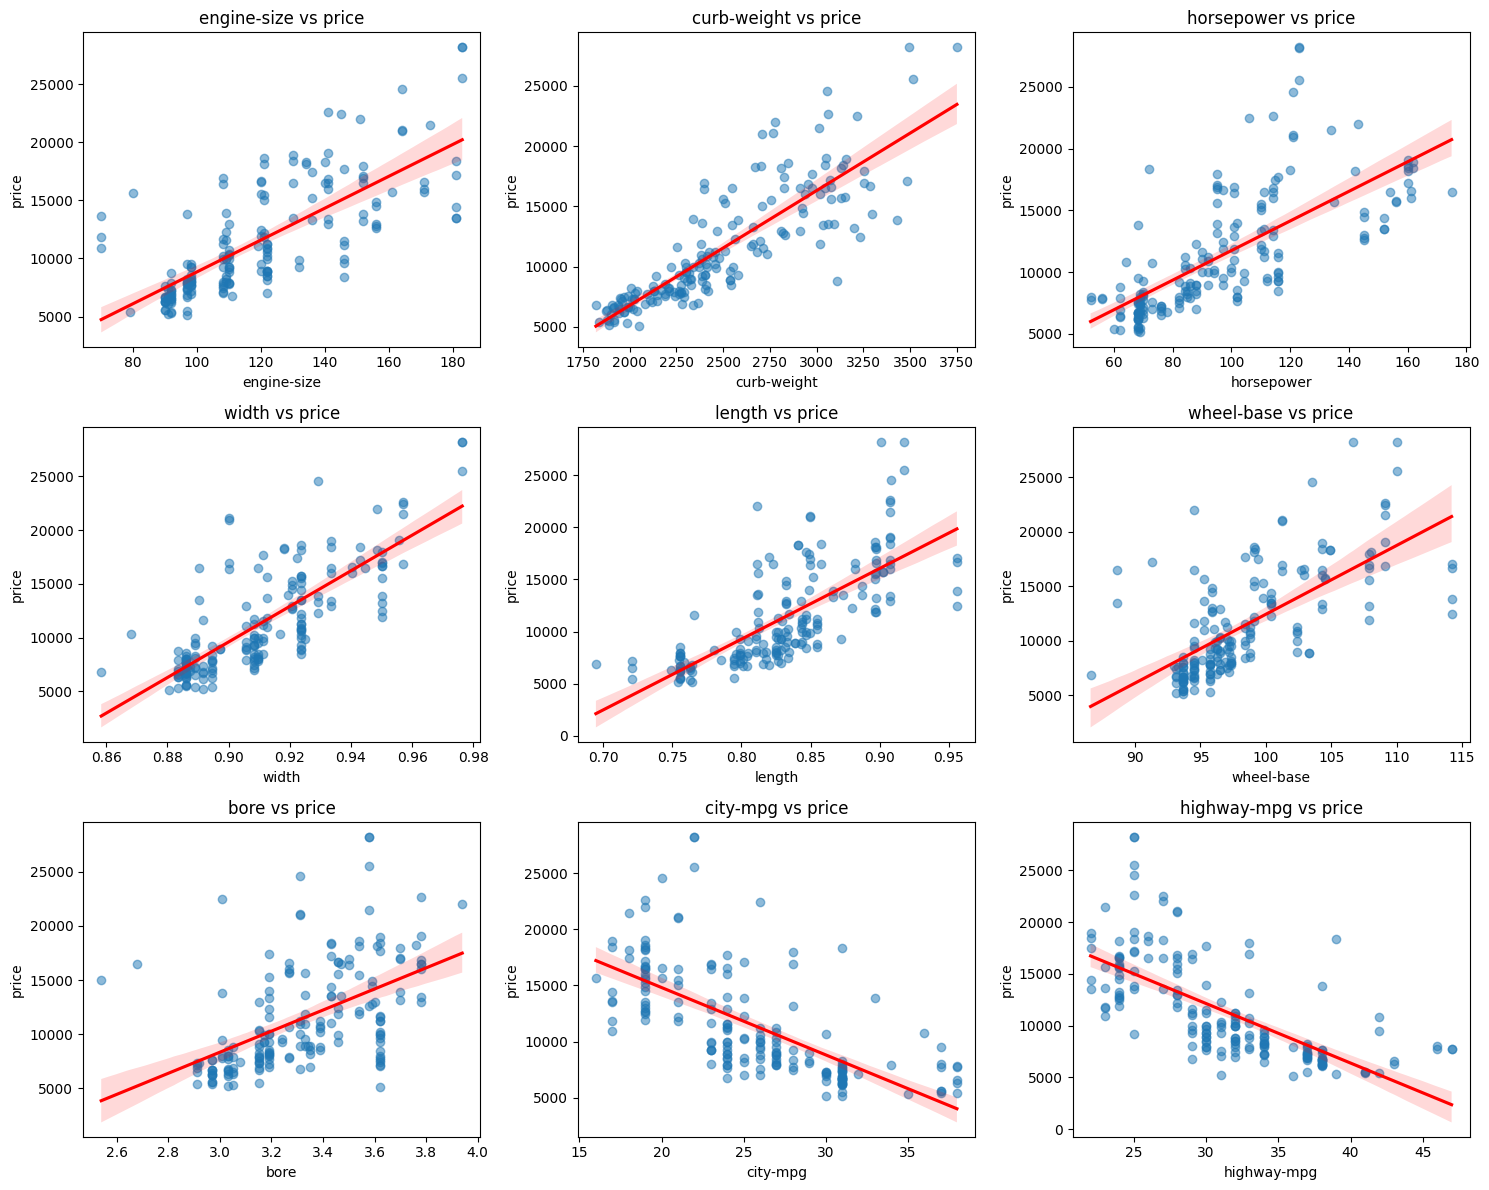

In [37]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))   # a 3x3 grid of empty plots
axes = axes.flatten()                              # turn the grid into  list of 9 slots

for ax, col in zip(axes, num_cols):                # pair each slot with a column name
    sns.regplot(x=col, y='price', data=df, ax=ax,
                scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
    ax.set_title(f'{col} vs price')

plt.tight_layout()
plt.show()

In [38]:
results = []
for col in num_cols:
    r, p = pearsonr(df[col], df['price'])          # r = strength, p = is it real?
    results.append({'variable': col, 'r': round(r, 2), 'p-value': p})

corr_table = pd.DataFrame(results).sort_values('r', key=abs, ascending=False)  # strongest first
print(corr_table)

      variable     r       p-value
1  curb-weight  0.85  1.257083e-51
3        width  0.78  8.108517e-39
0  engine-size  0.75  1.413498e-33
4       length  0.73  7.638256e-31
2   horsepower  0.71  4.455941e-29
8  highway-mpg -0.68  4.043797e-26
5   wheel-base  0.67  6.365054e-25
7     city-mpg -0.67  4.736732e-25
6         bore  0.53  3.644636e-14


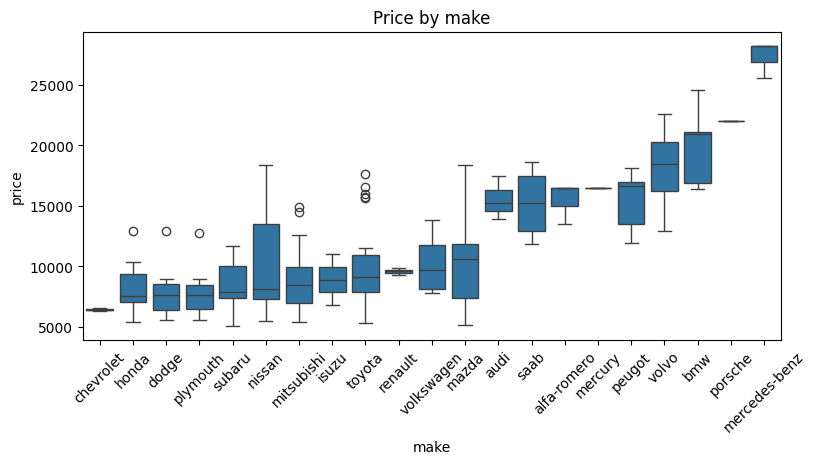

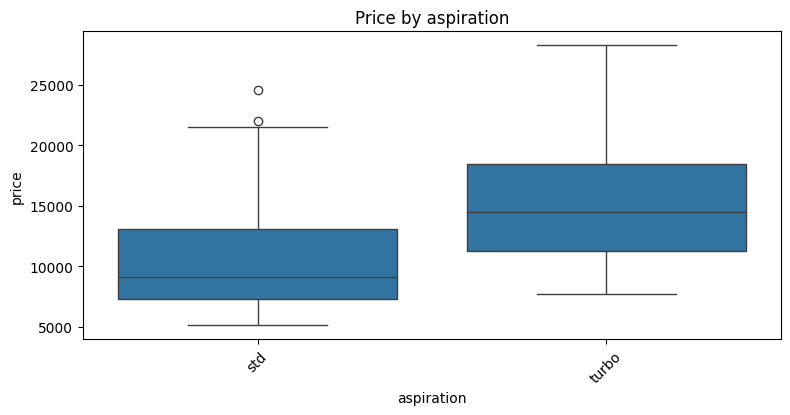

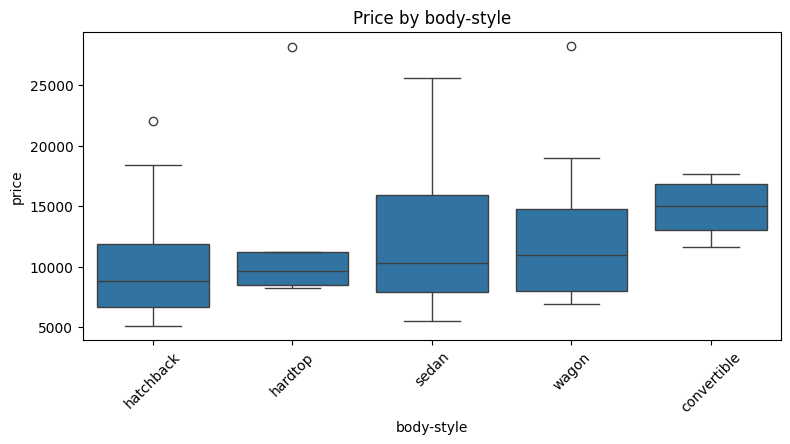

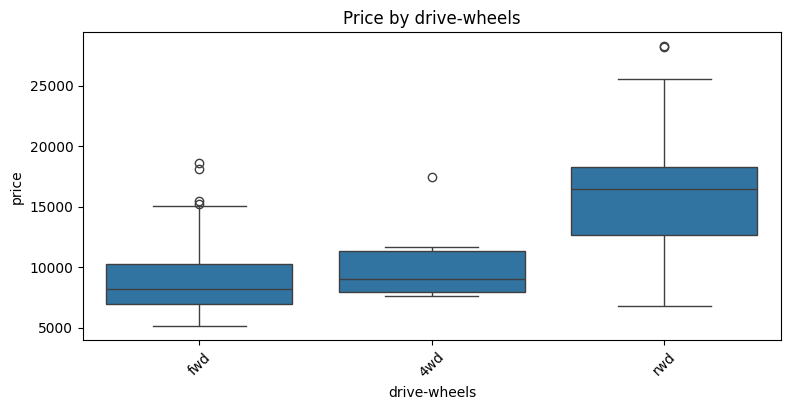

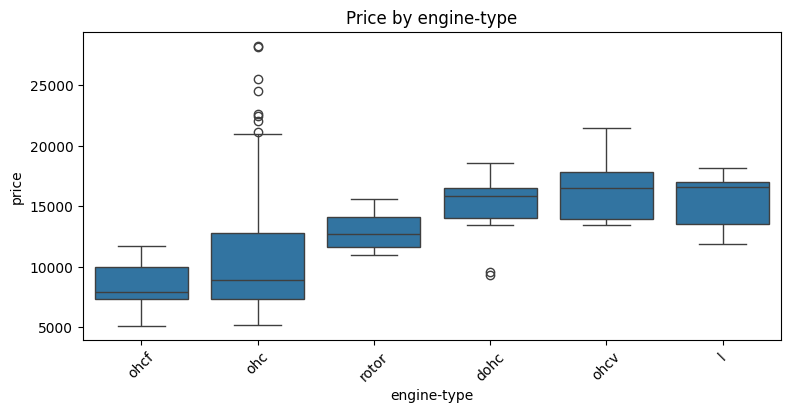

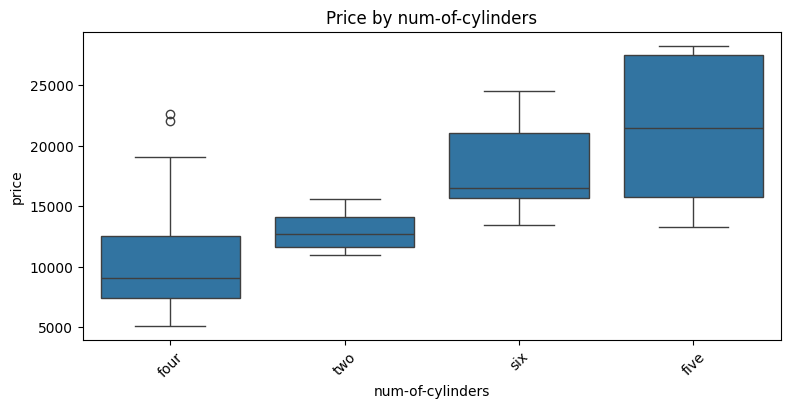

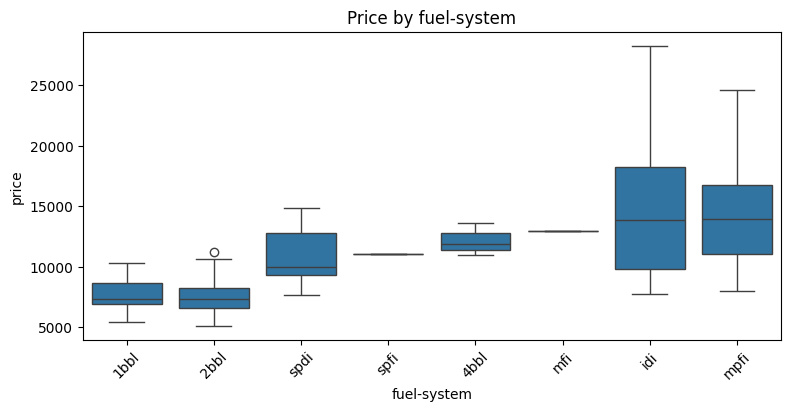

In [39]:
for col in cat_cols:
    plt.figure(figsize=(9, 4))
    order = df.groupby(col)['price'].median().sort_values().index    # cheapest group first
    sns.boxplot(x=col, y='price', data=df, order=order)
    plt.xticks(rotation=45)
    plt.title(f'Price by {col}')
    plt.show()

In [40]:
results = []
for col in cat_cols:
    groups = [g['price'].values for _, g in df.groupby(col)]    # one list of prices per group
    f_stat, p = f_oneway(*groups)
    results.append({'variable': col, 'F': round(f_stat, 1), 'p-value': p})

anova_table = pd.DataFrame(results).sort_values('F', ascending=False)
print(anova_table)

           variable     F       p-value
3      drive-wheels  72.4  1.050140e-23
1        aspiration  33.3  3.411831e-08
5  num-of-cylinders  29.3  2.108429e-15
6       fuel-system  22.6  1.657134e-21
0              make  15.8  2.979443e-28
4       engine-type   6.4  1.808437e-05
2        body-style   2.8  2.838900e-02


body-style    convertible  hardtop  hatchback  sedan  wagon
drive-wheels                                               
4wd                     0        0          1      3      4
fwd                     1        1         47     52     11
rwd                     3        4         17     27      9


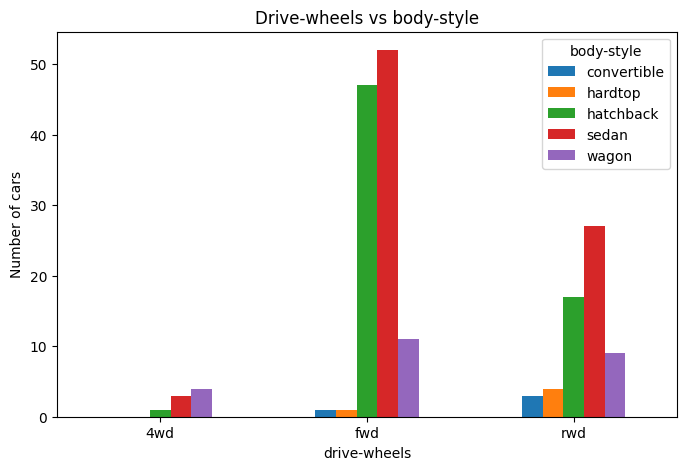

chi-square = 20.7, p-value = 0.0079
Cells with expected count below 5: 60 %


In [41]:
ct = pd.crosstab(df['drive-wheels'], df['body-style'])    # table of counts
print(ct)

ct.plot(kind='bar', figsize=(8, 5))                       # grouped bar chart
plt.ylabel('Number of cars')
plt.title('Drive-wheels vs body-style')
plt.xticks(rotation=0)
plt.show()

chi2, p, dof, expected = chi2_contingency(ct)
print(f"chi-square = {chi2:.1f}, p-value = {p:.4f}")
print("Cells with expected count below 5:", round((expected < 5).mean() * 100), "%")

I used scatter plots with a red trend line, and the Pearson correlation (r) with its p-value.

curb-weight has the tightest and strongest link (r = 0.85). Then width (0.78), engine-size (0.75), length (0.73) and horsepower (0.71). wheel-base (0.67) and bore (0.53) are positive but more scattered.

highway-mpg (-0.68) and city-mpg (-0.67) have a negative link: the more fuel a car uses, the higher the price.

All p-values are far below 0.05, so these links are not by chance. For engine-size and horsepower the dots spread out more at the high end, so the expensive cars are harder to predict. A link does not prove that one thing causes the other.

I used boxplots, with groups ordered from lowest to highest median price, and a one-way ANOVA test. A bigger F value means the groups differ more in price. If the p-value is below 0.05, price differs between the groups.

All 7 text variables have p-values below 0.05. The strongest is drive-wheels (F = 72.4), then aspiration (33.3), num-of-cylinders (29.3), fuel-system (22.6) and make (15.8). engine-type is weaker (6.4). body-style is the weakest (F = 2.8, p = 0.028), so it says little about price.

I compared drive-wheels and body-style with a count table, a grouped bar chart and a chi-square test.

Null hypothesis: the two variables are not linked. The chi-square value is 20.7 and the p-value is 0.0079, which is below 0.05, so the two variables are linked. For example, most fwd cars are sedans or hatchbacks, while rwd cars are spread more across body styles.

A warning: 60% of the cells have an expected count below 5, because some groups are small. This breaks a rule of the chi-square test, so the result is only a rough guide.

Question 5

In [42]:
df = pd.read_csv("Yine_Data.csv")
data = df.copy()       

In [43]:
cat_cols = data.select_dtypes(exclude='number').columns
for col in cat_cols:
    data[col] = LabelEncoder().fit_transform(data[col])  

X = data.drop(columns='price')                     
y = data['price']                    

curb-weight         0.804
horsepower          0.794
highway-mpg         0.759
city-mpg            0.630
width               0.628
engine-size         0.626
wheel-base          0.525
length              0.504
fuel-system         0.463
bore                0.447
make                0.411
drive-wheels        0.301
engine-type         0.168
num-of-cylinders    0.145
aspiration          0.083
body-style          0.037
dtype: float64


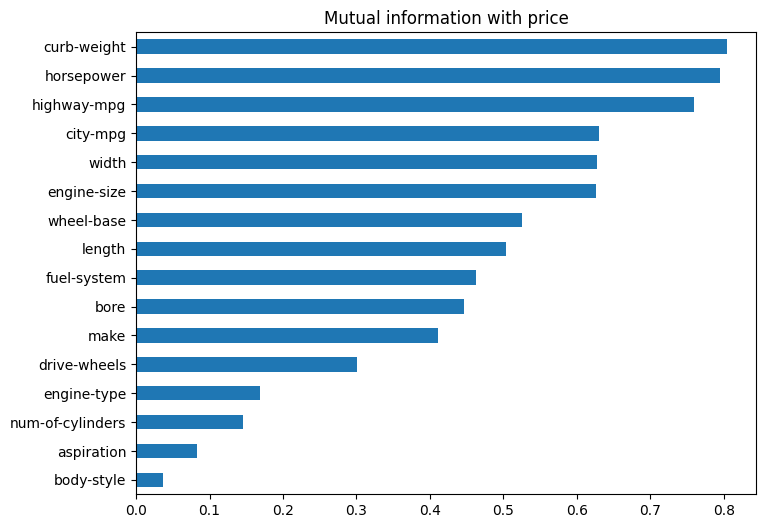

In [44]:
is_cat = [col in cat_cols for col in X.columns]     # True for the text columns

mi = mutual_info_regression(X, y, discrete_features=is_cat, random_state=0)
mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False)
print(mi_scores.round(3))

mi_scores.sort_values().plot(kind='barh', figsize=(8, 6))     # biggest bar at the top
plt.title('Mutual information with price')
plt.show()

In [45]:
num_features = [c for c in X.columns if c not in cat_cols]    # numeric columns only
F, p = f_regression(X[num_features], y)
f_scores = pd.Series(F, index=num_features).sort_values(ascending=False)
print(f_scores.round(1))

curb-weight    466.7
width          285.3
engine-size    226.7
length         199.2
horsepower     182.5
highway-mpg    156.1
city-mpg       147.0
wheel-base     145.9
bore            67.9
dtype: float64


In [46]:
top_num = [c for c in mi_scores.index if c not in cat_cols][:5]   # top 5 numeric by MI
print(df[top_num].corr().round(2))

             curb-weight  horsepower  highway-mpg  city-mpg  width
curb-weight         1.00        0.72        -0.74     -0.70   0.85
horsepower          0.72        1.00        -0.81     -0.84   0.60
highway-mpg        -0.74       -0.81         1.00      0.96  -0.59
city-mpg           -0.70       -0.84         0.96      1.00  -0.56
width               0.85        0.60        -0.59     -0.56   1.00


For feature selection I used two methods. Mutual information measures how much knowing a variable tells us about price. It works for both number and text columns, and it does not need a straight-line link. I label-encoded the text columns first.

The top variables are curb-weight (0.804), horsepower (0.794), highway-mpg (0.759), city-mpg (0.630), width (0.628) and engine-size (0.626). Among text columns the highest are fuel-system (0.463), make (0.411) and drive-wheels (0.301). The lowest are aspiration (0.083) and body-style (0.037).

The second method is the F-score from f_regression, for the number columns only. It measures the strength of the straight-line link with price. The top scores are curb-weight (466.7), width (285.3), engine-size (226.7), length (199.2) and horsepower (182.5). bore is the lowest (67.9).

Both methods put curb-weight first, so it is the most important variable. The orders differ a little after that, but they pick almost the same group of size and power variables.

I checked how the top variables relate to each other. city-mpg and highway-mpg are almost the same (0.96). curb-weight and width are also strongly linked (0.85), and horsepower is strongly linked to both fuel use columns (about -0.81 and -0.84). This means many of the top variables carry the same information, so they are not all separate drivers of price.

Main variables that affect car price: curb-weight (the strongest), horsepower, engine-size and width, which all measure the size and power of the car. Fuel use (highway-mpg and city-mpg) is also strongly linked, in the opposite direction. Among text variables, drive-wheels, fuel-system, make and number of cylinders matter most. body-style and aspiration matter least.